In [42]:
print("Hello World")

Hello World


In [43]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [44]:
#Load the data

df = pd.read_csv('emails.csv') 

df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [45]:
df.shape

(5172, 3002)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), str(1)
memory usage: 118.5 MB


In [47]:
df.dtypes

Email No.       str
the           int64
to            int64
ect           int64
and           int64
              ...  
military      int64
allowing      int64
ff            int64
dry           int64
Prediction    int64
Length: 3002, dtype: object

In [48]:
df.describe()

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [14]:
df.isnull().sum().sum()

np.int64(0)

In [18]:
df.columns.to_list()[-10:]

['connevey',
 'jay',
 'valued',
 'lay',
 'infrastructure',
 'military',
 'allowing',
 'ff',
 'dry',
 'Prediction']

In [20]:
#Preprocessing 

df.drop(columns=['Email No.']  , inplace=True) 





/var/folders/zs/vfn5k789363gmxvqm3wzwttw0000gn/T/ipykernel_19992/87530835.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Email No.']  , inplace=True)


In [21]:
df.drop_duplicates(inplace=True)

/var/folders/zs/vfn5k789363gmxvqm3wzwttw0000gn/T/ipykernel_19992/3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [23]:
target = 'Prediction'

X = df.drop(columns=target) 
y = df[target]

X = X.select_dtypes(include=np.number)

print("Feature Shape : " , X.shape) 
print("Target Shape : " , y.shape) 


print("\nClass Distribution:")
print(y.value_counts())

Feature Shape :  (4631, 3000)
Target Shape :  (4631,)

Class Distribution:
Prediction
0    3170
1    1461
Name: count, dtype: int64


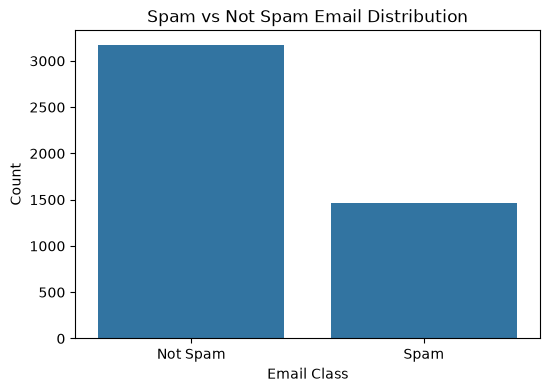

In [27]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("Spam vs Not Spam Email Distribution")

plt.xlabel("Email Class")

plt.ylabel("Count")

plt.xticks([0, 1], ['Not Spam', 'Spam'])

plt.show()

In [28]:
X_train , X_test , y_train , y_test = train_test_split(X , y , random_state=42 , test_size=0.2) 

print("Train Size : " , X_train.shape) 
print("Test Size : " , X_test.shape) 

Train Size :  (3704, 3000)
Test Size :  (927, 3000)


In [29]:
scaler = StandardScaler() 

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test) 

print("Feature scaling completed" ) 

print("Scaled Train Size : " , X_train_scaled.shape) 
print("Scaled Test Size : " , X_test_scaled.shape) 


Feature scaling completed
Scaled Train Size :  (3704, 3000)
Scaled Test Size :  (927, 3000)


In [34]:
knn = KNeighborsClassifier(n_neighbors=5) 

knn.fit(X_train_scaled , y_train)

knn_pred = knn.predict(X_test_scaled) 

knn_accuracy = accuracy_score(y_test , knn_pred)

print("Accuracy Score : " , knn_accuracy*100 ) 


print("\nClassification Report:")

print(classification_report(y_test, knn_pred))

Accuracy Score :  82.20064724919094

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.76      0.85       633
           1       0.65      0.95      0.77       294

    accuracy                           0.82       927
   macro avg       0.81      0.86      0.81       927
weighted avg       0.87      0.82      0.83       927



In [36]:
svm = SVC(kernel='linear') 

svm.fit(X_train_scaled , y_train) 

svm_pred = svm.predict(X_test_scaled) 


svm_accuracy = accuracy_score(y_test , svm_pred) 


print("accuracy_score :" , svm_accuracy) 

print("classification_report")
print(classification_report(y_test , svm_pred)) 

accuracy_score : 0.9546925566343042
classification_report
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       633
           1       0.92      0.94      0.93       294

    accuracy                           0.95       927
   macro avg       0.95      0.95      0.95       927
weighted avg       0.95      0.95      0.95       927



In [37]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],

    'Accuracy': [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],

    'Precision': [
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, svm_pred, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ]
})

print(results)

# Identify best model based on accuracy
best_model = results.loc[results['Accuracy'].idxmax()]

print("\nBest Model:", best_model['Model'])

  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.822006   0.651054  0.945578  0.771151
1   SVM  0.954693   0.922819  0.935374  0.929054

Best Model: SVM


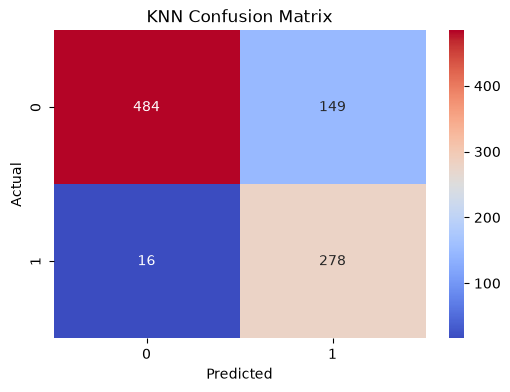

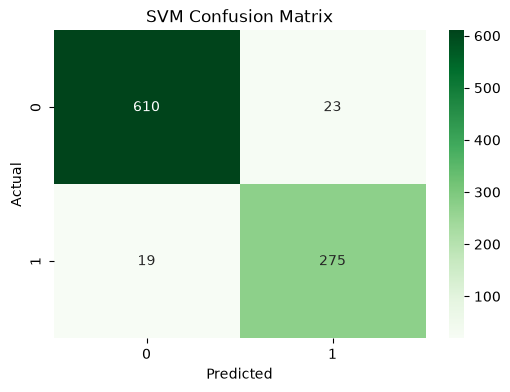

In [40]:
# KNN Confusion Matrix
cm_knn = confusion_matrix(y_test, knn_pred)

# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, svm_pred)

# Plot KNN
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='coolwarm'
)

plt.title("KNN Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


# Plot SVM
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("SVM Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

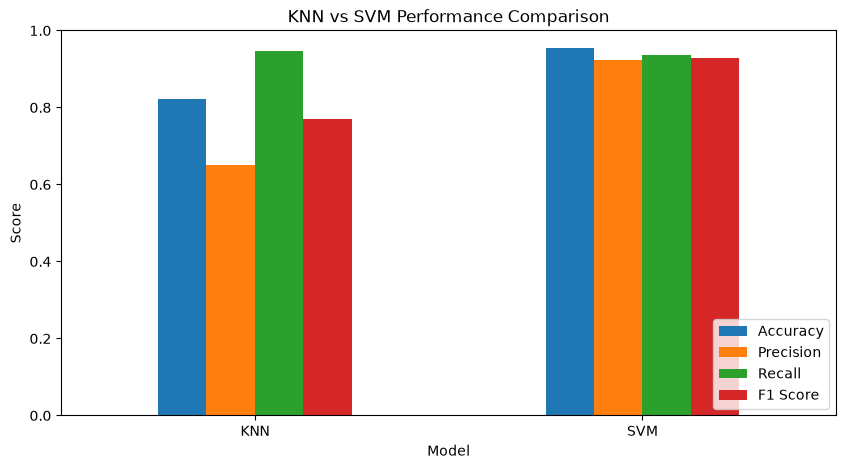

In [41]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("KNN vs SVM Performance Comparison")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc='lower right')

plt.show()